# Distribuição da receita anual estimada por bairro (Airbnb SP)

Réplica do `distribuicao_valor_m2_distrito.ipynb`, trocando o valor venal/m² do IPTU pela receita anual
estimada dos anúncios (`estimated_revenue_l365d`, Inside Airbnb). O bairro é o `neighbourhood_cleansed`, que em
São Paulo corresponde aos 96 distritos municipais.

A pergunta é a mesma: a **mediana/média por bairro** representa bem os anúncios, ou há bairros com dois grupos
distintos de receita (multimodais)?

## lib


In [1]:
import unicodedata
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy.stats import gaussian_kde, norm   # KDE (densidade suavizada) e pdf da normal (para desenhar as gaussianas do GMM)
from scipy.signal import find_peaks          # encontra máximos locais numa curva -> conta os picos do KDE
from sklearn.mixture import GaussianMixture  # mistura de gaussianas -> ajusta 2 grupos e mede a separação entre eles

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# raiz do repositório (funciona rodando de notebooks/, notebooks/initialAnalysis/ ou da raiz):
# sobe a árvore de diretórios até achar uma pasta que tenha data/ e src/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir() and (p / "src").is_dir())
PROC = ROOT / "data" / "processed"

AZUL, LARANJA, CINZA = "#2a78d6", "#eb6834", "#8a8984"   # paleta de referência (slots 1 e 2 + neutro)

## 1. Dados

In [2]:
COLS = ["id", "neighbourhood_cleansed", "room_type", "estimated_revenue_l365d"]
a = pd.read_csv(PROC / "Airbnb" / "listings_clean.csv", usecols=COLS)
a = a.rename(columns={"neighbourhood_cleansed": "bairro", "estimated_revenue_l365d": "receita"})

# receita zero = anúncio sem ocupação estimada no último ano (inativo); não tem log e não é o que
# queremos descrever, então sai da análise
n_zero = (a["receita"] == 0).sum()
r = a[a["receita"] > 0].copy()

# simplifica o tipo em dois grupos: imóvel inteiro × quarto (privativo, compartilhado ou de hotel)
r["tipo"] = np.where(r["room_type"] == "Entire home/apt", "imóvel inteiro", "quarto")

# corta só os extremos (0,1% de cada lado), como no notebook do IPTU
lo, hi = r["receita"].quantile([0.001, 0.999])
r = r[r["receita"].between(lo, hi)]
# trabalha em log10: a distribuição é muito assimétrica e em log os modos ficam separados e visíveis
r["log_rev"] = np.log10(r["receita"])

# região (Centro/Oeste/Sul/Norte/Leste) de cada bairro: os nomes do Airbnb vêm sem acento e em
# caixa mista, então normalizamos os dois lados (sem acento, maiúsculas) antes de casar
def chave(s):
    return unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().upper().strip()

regiao = pd.read_csv(PROC / "distrito_features.csv", usecols=["distrito", "regiao5"])
regiao = regiao.assign(k=regiao["distrito"].map(chave)).set_index("k")["regiao5"]
r["regiao"] = r["bairro"].map(chave).map(regiao)
assert r["regiao"].notna().all(), "bairro sem região"

print(f"anúncios: {len(a):,} | com receita zero (removidos): {n_zero:,}")
print(f"anúncios com receita > 0 após corte: {len(r):,} | bairros: {r['bairro'].nunique()}")
print(f"corte de extremos: R$ {lo:,.0f} a R$ {hi:,.0f} /ano")
r["receita"].describe(percentiles=[.05, .25, .5, .75, .95]).round(0)

anúncios: 36,257 | com receita zero (removidos): 2,864
anúncios com receita > 0 após corte: 33,326 | bairros: 95
corte de extremos: R$ 531 a R$ 334,199 /ano


count     33326.0
mean      33109.0
std       33876.0
min         531.0
5%         2100.0
25%        8352.0
50%       22248.0
75%       48031.0
95%       95902.0
max      333909.0
Name: receita, dtype: float64

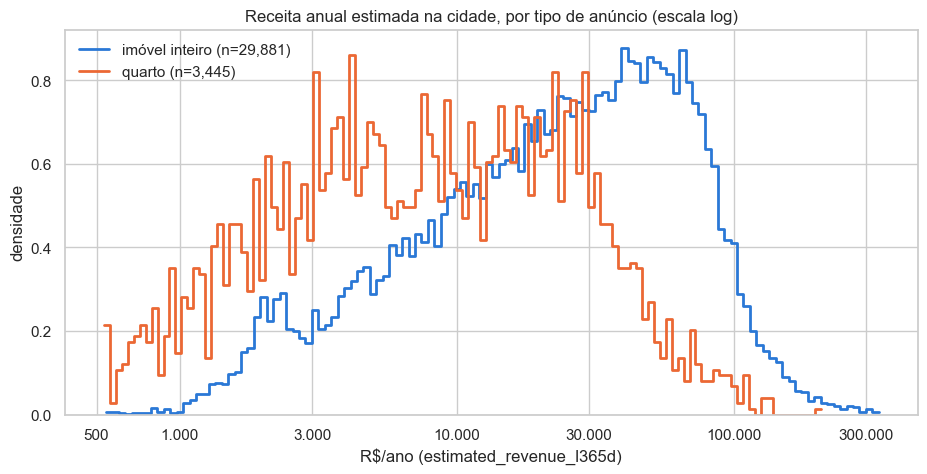

In [3]:
def eixo_reais(ax, axis="x"):
    """Os dados estão em log10; este formatter mostra no eixo o valor em R$ (10**v) com ponto de milhar."""
    fmt = mticker.FuncFormatter(lambda v, _: f"{10**v:,.0f}".replace(",", "."))
    (ax.xaxis if axis == "x" else ax.yaxis).set_major_formatter(fmt)

TICKS = np.log10([500, 1000, 3000, 10000, 30000, 100000, 300000])   # ticks em valores "redondos" de R$

fig, ax = plt.subplots(figsize=(11, 5))
# um histograma por tipo; stat="density" normaliza cada curva para área 1, assim dá para comparar
# as formas mesmo com quantidades muito diferentes de imóveis inteiros e quartos
for tipo, cor in (("imóvel inteiro", AZUL), ("quarto", LARANJA)):
    sns.histplot(r.loc[r["tipo"] == tipo, "log_rev"], bins=120, stat="density", element="step",
                 fill=False, linewidth=2, color=cor, label=f"{tipo} (n={(r['tipo'] == tipo).sum():,})", ax=ax)
ax.set_xticks(TICKS)
eixo_reais(ax)
ax.set(title="Receita anual estimada na cidade, por tipo de anúncio (escala log)",
       xlabel="R$/ano (estimated_revenue_l365d)", ylabel="densidade")
ax.legend(frameon=False)
plt.show()

## 2. Detecção de multimodalidade

Mesmos dois critérios do notebook do IPTU, que precisam concordar:

1. **Picos do KDE**: a densidade suavizada (em log10) tem ≥ 2 picos com proeminência de pelo menos 10% da altura máxima.
2. **Mistura de 2 gaussianas (GMM)**: as componentes estão separadas (D de Ashman > 2) e o grupo menor tem ≥ 10% dos anúncios.

Diferença em relação ao IPTU: lá cada distrito tinha milhares de imóveis; aqui vários bairros periféricos têm
só um punhado de anúncios. Com poucos pontos o KDE e o GMM viram ruído, então o diagnóstico (e os gráficos)
só considera bairros com pelo menos `MIN_ANUNCIOS = 30` (mesmo limiar do `airbnb_analysis.ipynb`).

In [4]:
MIN_ANUNCIOS = 30
cont = r["bairro"].value_counts()
validos = cont[cont >= MIN_ANUNCIOS].index
rv = r[r["bairro"].isin(validos)]
print(f"bairros com ≥ {MIN_ANUNCIOS} anúncios: {len(validos)} de {r['bairro'].nunique()} "
      f"({len(rv) / len(r):.1%} dos anúncios)")
print("fora do diagnóstico:", ", ".join(f"{b} ({n})" for b, n in cont[cont < MIN_ANUNCIOS].items()))

# grade comum de pontos (em log10) onde todas as densidades são avaliadas -> curvas comparáveis entre bairros
GRID = np.linspace(r["log_rev"].min(), r["log_rev"].max(), 600)
rng = np.random.default_rng(42)   # semente fixa: a amostragem (e portanto os resultados) é reprodutível
AMOSTRA = 20_000

def amostra(x):
    """Subamostra até 20 mil valores (aqui nenhum bairro passa disso; mantido por paridade com o IPTU)."""
    return x if len(x) <= AMOSTRA else rng.choice(x, AMOSTRA, replace=False)

# KDE de cada bairro (usado no ridgeline da seção 3)
kde = {d: gaussian_kde(amostra(g.values))(GRID) for d, g in rv.groupby("bairro")["log_rev"]}
# resumo "de um número só" que estamos questionando: média e mediana por bairro (em R$, não em log)
resumo = rv.groupby("bairro").agg(n=("receita", "size"), media=("receita", "mean"),
                                  mediana=("receita", "median"), regiao=("regiao", "first"))

bairros com ≥ 30 anúncios: 54 de 95 (98.4% dos anúncios)
fora do diagnóstico: Vila Maria (28), Parelheiros (28), Campo Limpo (27), Pirituba (25), Cangaiba (24), Sao Domingos (23), Freguesia Do O (22), Grajau (20), Itaquera (20), Artur Alvim (19), Cachoeirinha (18), Mandaqui (17), Vila Medeiros (16), Sao Miguel (15), Jaguara (15), Sapopemba (14), Anhanguera (12), Jaragua (12), Jose Bonifacio (12), Carrao (12), Ermelino Matarazzo (12), Parque Do Carmo (11), Aricanduva (11), Ponte Rasa (11), Vila Jacui (10), Limao (10), Raposo Tavares (9), Jacana (8), Sao Mateus (8), Marsilac (8), Jardim Helena (7), Jardim Angela (7), Lajeado (7), Guaianases (6), Perus (6), Sao Rafael (4), Vila Curuca (3), Capao Redondo (2), Brasilandia (2), Cidade Tiradentes (1), Itaim Paulista (1)


In [5]:
# limiares do critério de multimodalidade (ver markdown acima)
#   PROEMINENCIA: um pico só conta se "se destaca" pelo menos 10% da altura máxima do KDE
#   D_MIN:        separação mínima (D de Ashman) entre as duas gaussianas
#   PESO_MIN:     o grupo menor precisa ter pelo menos 10% dos anúncios
PROEMINENCIA, D_MIN, PESO_MIN = 0.10, 2.0, 0.10

def diagnostico(x, grid=None):
    """Recebe os valores (em log10) de um grupo e devolve as métricas dos dois critérios."""
    grid = GRID if grid is None else grid
    xs = amostra(x)

    # --- critério 1: picos do KDE ---
    # estima a densidade e conta os máximos locais; a proeminência mede quanto o pico sobe acima do
    # "vale" que o separa do pico vizinho, então ondulações pequenas (ruído) são descartadas
    dens = gaussian_kde(xs)(grid)
    picos, _ = find_peaks(dens, prominence=PROEMINENCIA * dens.max())

    # --- critério 2: mistura de 2 gaussianas (GMM) ---
    # n_init=3: roda o EM 3 vezes com inicializações diferentes e fica com o melhor ajuste
    gm = GaussianMixture(2, n_init=3, random_state=0).fit(xs.reshape(-1, 1))
    # ordena as componentes pela média, para que a componente 0 seja sempre o modo baixo e a 1 o modo alto
    ordem = np.argsort(gm.means_.ravel())
    mu, sd, w = gm.means_.ravel()[ordem], np.sqrt(gm.covariances_.ravel())[ordem], gm.weights_[ordem]
    # D de Ashman: distância entre as médias medida em "desvios-padrão combinados".
    # D > 2 => as duas gaussianas são separadas o suficiente para a soma ter dois picos (bimodal de verdade);
    # D pequeno => as duas componentes se sobrepõem e só estão modelando assimetria/cauda.
    D = np.sqrt(2) * abs(mu[1] - mu[0]) / np.sqrt(sd[0]**2 + sd[1]**2)

    return pd.Series({"n_picos": len(picos),
                      "modos_kde": np.round(10**grid[picos], -2).astype(int).tolist(),   # posição dos picos em R$/ano
                      "ashman_D": D, "peso_menor": w.min(),
                      "modo1": 10**mu[0], "modo2": 10**mu[1], "peso1": w[0], "peso2": w[1],   # de volta para R$
                      "_gmm": (mu, sd, w)})   # parâmetros crus, guardados para desenhar as gaussianas depois

# aplica o diagnóstico em cada bairro; unstack transforma a Series de Series em colunas
diag = rv.groupby("bairro")["log_rev"].apply(lambda s: diagnostico(s.values)).unstack()
diag = resumo.join(diag)
# regra final: só é multimodal se os DOIS critérios concordam
#   (KDE com ≥ 2 picos) E (gaussianas bem separadas) E (grupo menor não é uma caudinha)
diag["multimodal"] = (diag["n_picos"] >= 2) & (diag["ashman_D"] > D_MIN) & (diag["peso_menor"] >= PESO_MIN)

# mostra quantos bairros cada critério pegaria sozinho, para ver o efeito de exigir os dois
print(f"bairros multimodais: {diag['multimodal'].sum()} de {len(diag)}")
print(f"  só ≥2 picos no KDE: {(diag['n_picos'] >= 2).sum()} | só GMM (D>2 e peso≥10%): "
      f"{((diag['ashman_D'] > D_MIN) & (diag['peso_menor'] >= PESO_MIN)).sum()}")

bairros multimodais: 0 de 54
  só ≥2 picos no KDE: 0 | só GMM (D>2 e peso≥10%): 47


## 3. Distribuição por bairro: ridgeline por região

Uma curva de densidade (KDE em log10) por bairro, ordenadas pela mediana. A linha vertical marca a
**mediana** e o losango marca a **média**. Bairros em laranja são os sinalizados como multimodais na seção 2.

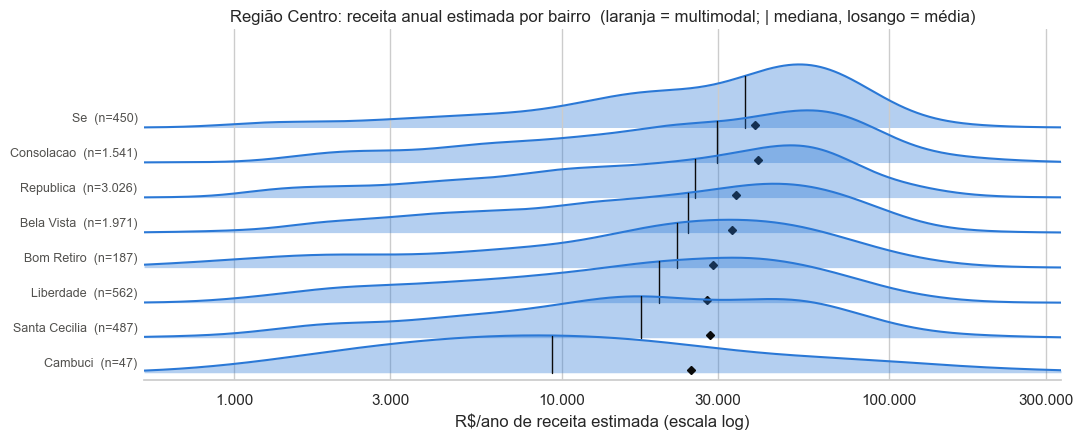

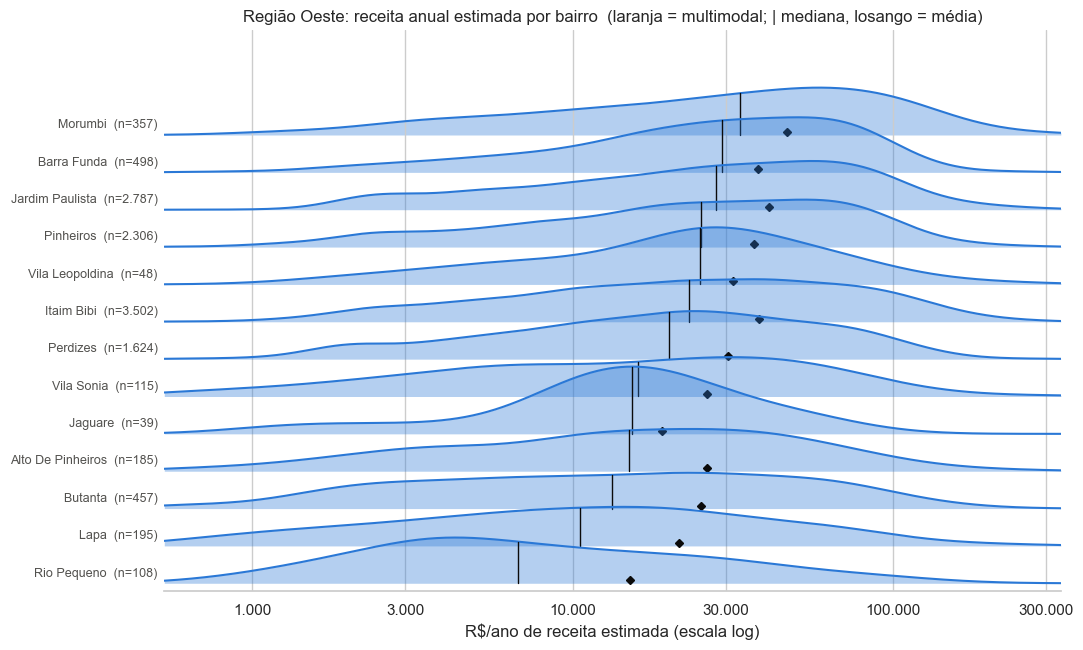

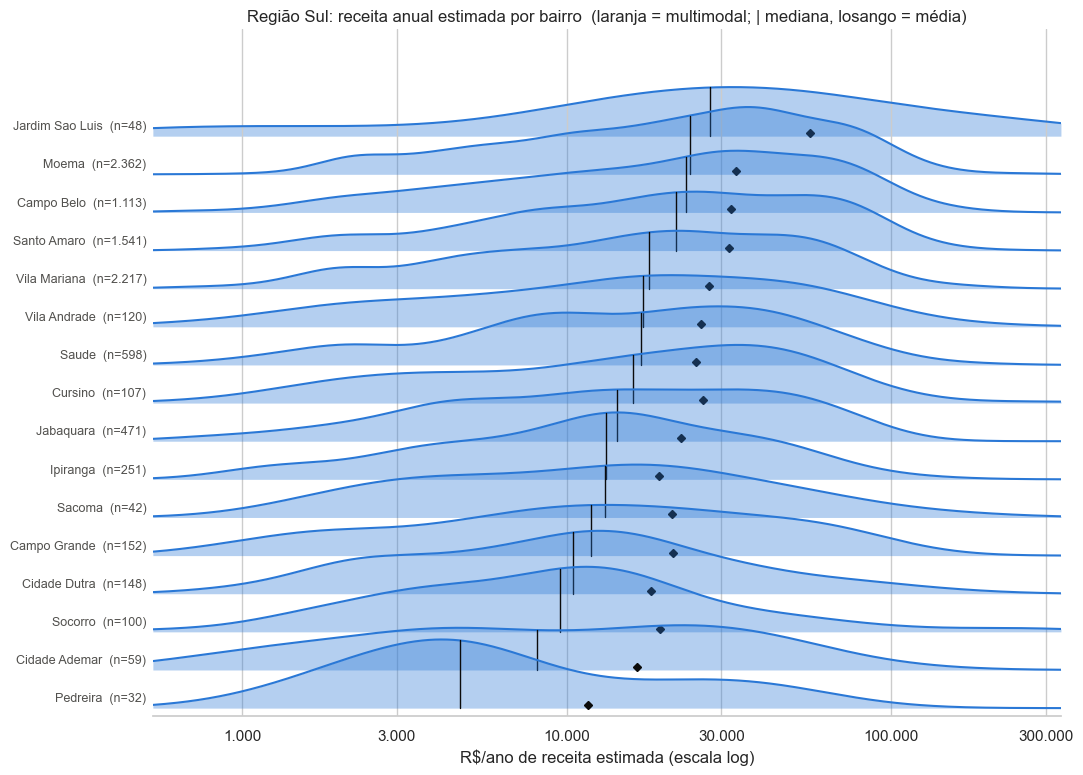

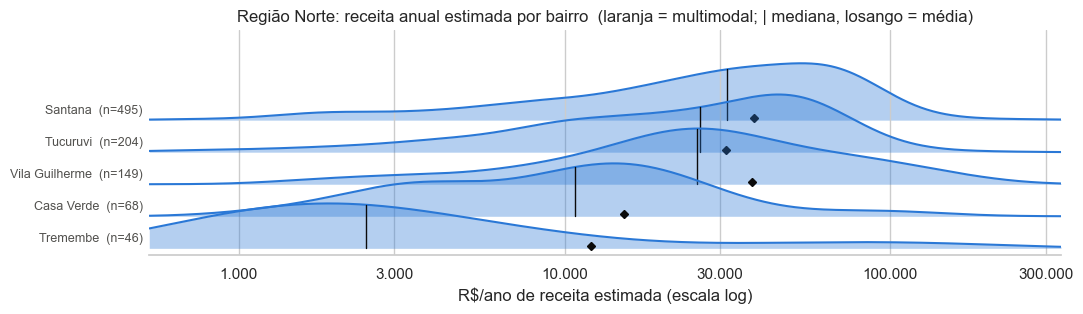

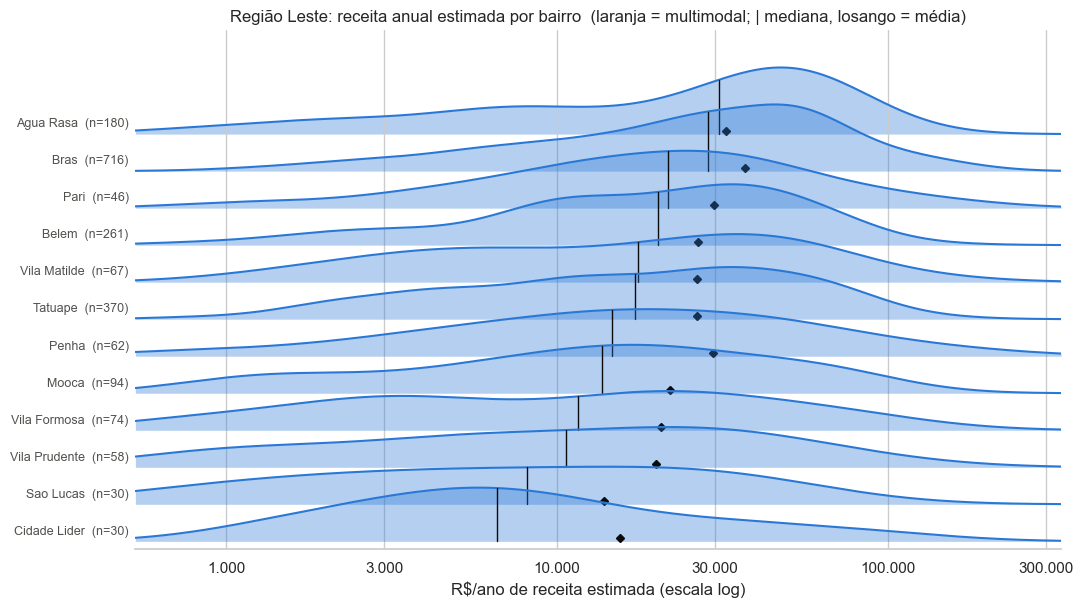

In [6]:
def ridgeline(bairros, titulo, sobreposicao=1.8, xlabel="R$/ano de receita estimada (escala log)"):
    """Uma curva de densidade por bairro, empilhadas verticalmente (cada uma numa "linha" y0)."""
    bairros = list(bairros)
    fig, ax = plt.subplots(figsize=(11, 0.42 * len(bairros) + 1.2))
    # mesma escala para todas as curvas (pela maior densidade): alturas comparáveis entre bairros
    escala = max(kde[d].max() for d in bairros)
    for i, d in enumerate(bairros):
        y0 = len(bairros) - 1 - i   # primeiro bairro da lista fica no topo
        dens = kde[d] / escala * sobreposicao   # sobreposicao > 1 deixa as curvas invadirem a linha de cima
        cor = LARANJA if diag.at[d, "multimodal"] else AZUL
        # zorder crescente: cada curva é desenhada por cima da anterior (efeito "cordilheira")
        ax.fill_between(GRID, y0, y0 + dens, color=cor, alpha=0.35, linewidth=0, zorder=2 * i)
        ax.plot(GRID, y0 + dens, color=cor, linewidth=1.5, zorder=2 * i + 1)
        # mediana = traço vertical até a curva; média = losango na base
        med, mea = np.log10(diag.at[d, "mediana"]), np.log10(diag.at[d, "media"])
        ax.plot([med, med], [y0, y0 + np.interp(med, GRID, dens)], color="#0b0b0b", linewidth=1, zorder=2 * i + 1)
        ax.plot(mea, y0 + 0.08, marker="D", markersize=4, color="#0b0b0b", zorder=2 * i + 1)
        ax.text(GRID[0] - 0.02, y0 + 0.1, f"{d}  (n={diag.at[d, 'n']:,})".replace(",", "."),
                ha="right", va="bottom", fontsize=9, color="#52514e")
    ax.set_yticks([]); ax.set_xticks(TICKS); eixo_reais(ax)
    ax.set_xlim(GRID[0], GRID[-1]); ax.set_ylim(-0.2, len(bairros) + sobreposicao)
    ax.set(title=titulo, xlabel=xlabel)
    ax.grid(axis="y", visible=False)
    sns.despine(ax=ax, left=True)
    plt.tight_layout(); plt.show()

# um gráfico por região, bairros da maior para a menor receita mediana
for reg in ["Centro", "Oeste", "Sul", "Norte", "Leste"]:
    ds = diag[diag["regiao"] == reg].sort_values("mediana", ascending=False).index
    if len(ds):
        ridgeline(ds, f"Região {reg}: receita anual estimada por bairro  (laranja = multimodal; | mediana, losango = média)")

### Tabela: bairros multimodais

In [7]:
# tabela dos bairros que passaram nos dois critérios, do mais separado (maior D) para o menos
cols = ["regiao", "n", "media", "mediana", "modos_kde", "modo1", "peso1", "modo2", "peso2", "ashman_D"]
tab_multi = diag.loc[diag["multimodal"], cols].sort_values("ashman_D", ascending=False)
tab_multi.style.format({"media": "{:,.0f}", "mediana": "{:,.0f}", "modo1": "{:,.0f}", "modo2": "{:,.0f}",
                        "peso1": "{:.0%}", "peso2": "{:.0%}", "ashman_D": "{:.2f}", "n": "{:,}"})

,regiao,n,media,mediana,modos_kde,modo1,peso1,modo2,peso2,ashman_D
bairro,,,,,,,,,,


### Detalhe dos multimodais: histograma + as duas gaussianas

Para cada bairro sinalizado: o histograma (log), as duas componentes do GMM (azul e laranja) e as linhas
da **média** (tracejada) e da **mediana** (contínua). Quando elas caem entre os dois picos, o resumo de um número
só não representa nenhum dos dois grupos.

In [8]:
def painel_gmm(bairros, ncols=3, col="log_rev",
               titulo="Bairros multimodais: componentes do GMM  (— mediana, - - média)"):
    """Grade de painéis: histograma do bairro + as duas gaussianas ajustadas pelo GMM.

    Serve para conferir visualmente o diagnóstico: se as duas curvas coloridas cobrem dois "morros"
    distintos do histograma, a bimodalidade é real; se se sobrepõem, o GMM só está modelando cauda.
    """
    bairros = list(bairros)
    if not bairros:
        print("nenhum bairro multimodal"); return
    nrows = int(np.ceil(len(bairros) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 3.4 * nrows), squeeze=False)
    for ax, d in zip(axes.flat, bairros):
        x = rv.loc[rv["bairro"] == d, col].dropna()
        ax.hist(x, bins=min(80, max(15, len(x) // 10)), density=True, color=CINZA, alpha=0.35)
        mu, sd, w = diag.at[d, "_gmm"]
        # cada componente é desenhada multiplicada pelo seu peso: a soma das duas curvas reproduz a mistura
        for k, cor in enumerate((AZUL, LARANJA)):
            ax.plot(GRID, w[k] * norm.pdf(GRID, mu[k], sd[k]), color=cor, linewidth=2,
                    label=f"R$ {10**mu[k]:,.0f} ({w[k]:.0%})".replace(",", "."))
        # média (tracejada) e mediana (contínua): queremos ver se caem no vale entre as duas gaussianas
        ax.axvline(np.log10(diag.at[d, "media"]), color="#0b0b0b", linestyle="--", linewidth=1)
        ax.axvline(np.log10(diag.at[d, "mediana"]), color="#0b0b0b", linewidth=1)
        ax.set_xticks(TICKS); eixo_reais(ax); ax.tick_params(axis="x", labelsize=8, rotation=45)
        ax.set_xlim(x.quantile(0.002) - 0.05, x.quantile(0.998) + 0.05)   # zoom no intervalo onde há dados
        ax.set_title(f"{d}  (n={diag.at[d, 'n']:,}, D={diag.at[d, 'ashman_D']:.1f})", fontsize=11)
        ax.set_yticks([]); ax.legend(frameon=False, fontsize=8)
    for ax in axes.flat[len(bairros):]:   # esconde painéis vazios da última linha
        ax.axis("off")
    fig.suptitle(titulo, y=1.0)
    plt.tight_layout(); plt.show()

painel_gmm(tab_multi.index)

nenhum bairro multimodal


## Leitura

Na execução de validação (listings de jun/2026), **nenhum bairro** passou nos dois critérios: o KDE não acha um
segundo pico em nenhum dos 54 bairros com ≥ 30 anúncios. O GMM sozinho marcaria 47, mas isso é a **cauda
esquerda** da distribuição em log (anúncios com poucas noites ocupadas no ano, assimetria negativa), não um segundo
grupo. Para a receita, então, a mediana por bairro é um resumo razoável (a média em R$ fica acima dela, puxada pelos
anúncios de receita muito alta).